# Sentiment Analysis with LLMs: Airline Customer Tweets

**Business problem.** An airline's social media team receives thousands of tweets a day. It needs to know how customers feel, what went wrong, and which tweets need a human reply within the hour.

**What this notebook does**

1. Prepares the Twitter US Airline Sentiment data (Kaggle) and creates fixed development and test sets.
2. Trains a classic baseline (TF-IDF with logistic regression).
3. Labels the test set with several LLMs through OpenRouter, using one labeling prompt.
4. Evaluates every approach against the human labels (accuracy, macro-F1, confusion matrices, complaint reasons, calibration, consistency, cost, and speed).
5. Exports disagreements for error analysis.

**Before you run it**

* Install the packages: `pip install openai pandas scikit-learn matplotlib`
* Store your OpenRouter key in an environment variable called `OPENROUTER_API_KEY`. Never type the key into the notebook.
    * macOS or Linux: `export OPENROUTER_API_KEY="..."` in the terminal, then start Jupyter from that terminal.
    * Windows: `setx OPENROUTER_API_KEY "..."`, then open a new terminal and start Jupyter.
* Put `Tweets.csv` from Kaggle ("Twitter US Airline Sentiment") in the same folder as this notebook. If the file is missing, the notebook tries to download a public copy.

**Cost.** With the default settings (500 test tweets, three models, plus a pilot and a consistency run), the whole notebook should cost well under US$1. Step 5 prints an estimate before any paid call is made.

All LLM results are saved in the `results/` folder as they arrive. If a run stops halfway, run the cell again and it continues where it stopped, without paying twice.

In [2]:
# %pip install openai

  Using cached openai-3.20.0-py3-none-any.whl.metadata (44 kB)
  Using cached httpx2-2.13.1-py3-none-any.whl.metadata (9.8 kB)
  Using cached httpcore2-2.13.1-py3-none-any.whl.metadata (26 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
Using cached openai-3.20.0-py3-none-any.whl (2.1 MB)
Using cached httpx2-2.13.1-py3-none-any.whl (95 kB)
Using cached httpcore2-2.13.1-py3-none-any.whl (83 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 15.9 MB/s  0:00:00
Using cached idna-3.20-py3-none-any.whl (69 kB)
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [openai]━━ 10/11 [openai]e2]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, json, re, time, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, cohen_kappa_score)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

## Settings

Change the models, sample sizes, or batch size here. Model IDs come from [openrouter.ai/models](https://openrouter.ai/models). Step 4 checks that each ID exists and prints its current price.

In [23]:
MODELS = [
    "anthropic/claude-haiku-4.5",
    "deepseek/deepseek-v4.1-flash",
    "moonshotai/kimi-k2.6",
]

MODEL_OPTIONS = {
       "deepseek/deepseek-v4.1-flash": {"reasoning": {"enabled": False}},
       "moonshotai/kimi-k2.6": {"reasoning": {"enabled": False}},
}


DATA_PATH   = "/Users/shailendra/Documents/Data Science/Python/Code/LLM Sentiment Analysis/tweets.csv"
#DATA_URL    = ("https://raw.githubusercontent.com/ruchitgandhi/"
#               "Twitter-Airline-Sentiment-Analysis/master/Tweets.csv")  # used only if Tweets.csv is missing

TEST_SIZE   = 500    # tweets used for the final evaluation
DEV_SIZE    = 100    # tweets used to try out and improve the prompt
CONSISTENCY_SIZE = 100  # test tweets labeled a second time to measure run-to-run agreement
BATCH_SIZE  = 25     # tweets per API request
MAX_TOKENS  = 6000   # upper limit on the length of each model reply
MAX_RETRIES = 3
RANDOM_SEED = 42

RESULTS_DIR = Path("/Users/shailendra/Documents/Data Science/Python/Code/LLM Sentiment Analysis/results")
RESULTS_DIR.mkdir(exist_ok=True)

LABELS  = ["negative", "neutral", "positive"]
REASONS = ["Customer Service Issue", "Late Flight", "Cancelled Flight", "Lost Luggage",
           "Damaged Luggage", "Bad Flight", "Flight Booking Problems",
           "Flight Attendant Complaints", "longlines", "Can't Tell"]

## Step 1. Prepare the data

We remove duplicate tweets and then split the data into three parts:

| Part | Size | Used by |
|---|---|---|
| Test set | 500 | every approach, for the final evaluation only |
| Development set | 100 | the LLMs, to try out the prompt (Step 6) |
| Training set | the rest | the classic baseline only |

The LLMs are not trained on our data, so they need no training set. They must still be evaluated on the same held-out test set as the baseline, or the comparison would be unfair. The development set exists so that we can improve the prompt without looking at test results.

In [13]:
if not Path(DATA_PATH).exists():
    print("Tweets.csv not found; downloading a public copy ...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw = pd.read_csv(DATA_PATH)
df = raw.drop_duplicates("text").reset_index(drop=True)
print(f"{len(raw):,} tweets loaded, {len(df):,} after removing duplicates\n")

test = df.sample(TEST_SIZE, random_state=RANDOM_SEED)
rest = df.drop(test.index)
dev  = rest.sample(DEV_SIZE, random_state=RANDOM_SEED)
train = rest.drop(dev.index)

test  = test.reset_index(drop=True)
dev   = dev.reset_index(drop=True)
train = train.reset_index(drop=True)
test["id"] = [f"T{i:04d}" for i in range(len(test))]
dev["id"]  = [f"D{i:04d}" for i in range(len(dev))]

summary = pd.DataFrame({
    "full data": df["airline_sentiment"].value_counts(normalize=True),
    "test set":  test["airline_sentiment"].value_counts(normalize=True),
}).loc[LABELS].round(3)
print(f"train {len(train):,} | dev {len(dev)} | test {len(test)}\n")
print("Share of each sentiment class")
print(summary)

14,640 tweets loaded, 14,427 after removing duplicates

train 13,827 | dev 100 | test 500

Share of each sentiment class
                   full data  test set
airline_sentiment                     
negative               0.629     0.632
neutral                0.212     0.200
positive               0.159     0.168


**Note.** About two thirds of the tweets are negative. A "model" that always answers *negative* would already reach about 63% accuracy. That is why we report macro-F1, which gives each class equal weight, alongside accuracy.

## Step 2. Classic baseline: TF-IDF with logistic regression

It learns from the roughly 13,800 labeled training tweets.

In [14]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vectorizer.fit_transform(train["text"])
X_test  = vectorizer.transform(test["text"])

baseline = LogisticRegression(max_iter=2000, class_weight="balanced", C=3.0)
t0 = time.time()
baseline.fit(X_train, train["airline_sentiment"])
test["pred_baseline"] = baseline.predict(X_test)
print(f"Trained and predicted in {time.time() - t0:.1f} seconds, at no API cost\n")
print(classification_report(test["airline_sentiment"], test["pred_baseline"], digits=3))

Trained and predicted in 0.2 seconds, at no API cost

              precision    recall  f1-score   support

    negative      0.903     0.858     0.880       316
     neutral      0.615     0.670     0.641       100
    positive      0.681     0.738     0.709        84

    accuracy                          0.800       500
   macro avg      0.733     0.755     0.743       500
weighted avg      0.808     0.800     0.803       500



## Step 3. The labeling prompt

The prompt is the labeling guideline written for a model. Each numbered part settles a question that human annotators would also have to agree on. You can change one part at a time and measure the effect on the development set.

In [15]:
PROMPT = """You are a customer-experience analyst agent for an airline social-media team.
Your job is to triage customer tweets so the team knows how customers feel,
what went wrong, and which tweets need a fast human response.

For EACH tweet, decide:

1. sentiment: exactly one of "negative", "neutral", "positive".
   - negative: the customer expresses dissatisfaction, frustration, complaint, or a problem.
   - positive: the customer expresses praise, thanks, satisfaction, or delight.
   - neutral: a question, request for information, factual statement, or no clear emotion.
   Judge the customer's attitude toward the airline. Sarcasm counts as its real meaning
   (for example, "Great, another delay" is negative).

2. negative_reason: only if sentiment is "negative", choose exactly one of:
   "Customer Service Issue", "Late Flight", "Cancelled Flight", "Lost Luggage",
   "Damaged Luggage", "Bad Flight", "Flight Booking Problems",
   "Flight Attendant Complaints", "longlines", "Can't Tell".
   Use "Can't Tell" when the tweet is negative but the cause is unclear.
   If sentiment is not negative, use null.

3. escalate: true if a human agent should respond within the hour because the customer
   has an active, time-sensitive problem (stranded, missed connection, flight cancelled
   today, cannot rebook, lost bag while travelling, safety concern). Otherwise false.

4. confidence: your confidence in the sentiment label, from 0.0 to 1.0.

5. rationale: at most 15 words explaining the decision.

Output one JSON object per tweet, one per line (JSON Lines), with keys:
{"id": ..., "sentiment": ..., "negative_reason": ..., "escalate": ..., "confidence": ..., "rationale": ...}
Output only the JSON lines, with no other text."""

## Step 4. Connect to OpenRouter

OpenRouter uses the same interface as the OpenAI library, so we only change the server address. This cell also checks that every model ID exists and reads its current price.

In [6]:
from openai import OpenAI

if not os.environ.get("OPENROUTER_API_KEY"):
    raise RuntimeError("OPENROUTER_API_KEY is not set. See the instructions at the top of the notebook.")

client = OpenAI(base_url="https://openrouter.ai/api/v1",
                api_key=os.environ["OPENROUTER_API_KEY"])

def fetch_prices():
    """Price per token (USD) for every OpenRouter model, from the public model list."""
    with urllib.request.urlopen("https://openrouter.ai/api/v1/models", timeout=30) as r:
        data = json.load(r)["data"]
    return {m["id"]: {"input": float(m["pricing"]["prompt"]),
                      "output": float(m["pricing"]["completion"])} for m in data}

try:
    PRICES = fetch_prices()
    rows = []
    for m in MODELS:
        if m not in PRICES:
            raise ValueError(f"Model ID not found on OpenRouter: {m}. Check openrouter.ai/models.")
        rows.append({"model": m,
                     "input $/M tokens": PRICES[m]["input"] * 1e6,
                     "output $/M tokens": PRICES[m]["output"] * 1e6})
    print(pd.DataFrame(rows).round(3).to_string(index=False))
except ValueError:
    raise
except Exception as e:
    PRICES = {}
    print("Could not download prices; costs will come from API responses only.", e)

                       model  input $/M tokens  output $/M tokens
  anthropic/claude-haiku-4.5              1.00               5.00
deepseek/deepseek-v4.1-flash              0.30               1.20
        moonshotai/kimi-k2.6              0.65               3.41


### Helper functions

These functions send tweets in batches, check every answer, retry failures, and save results to disk. Do not change them, but it is worth reading `validate`, because it shows how much checking an LLM's output needs before it can be trusted.

In [21]:
USAGE_LOG = RESULTS_DIR / "usage_log.csv"

def safe_name(model):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", model)

def format_batch(batch):
    return "\n".join(json.dumps({"id": r.id, "airline": r.airline, "text": r.text}, ensure_ascii=False)
                     for r in batch.itertuples())

def parse_lines(text):
    """Pull every JSON object out of the reply, ignoring code fences or stray text."""
    out = []
    for line in (text or "").splitlines():
        line = line.strip().rstrip(",")
        if line.startswith("{"):
            try:
                out.append(json.loads(line))
            except json.JSONDecodeError:
                pass
    return out

def validate(item, expected_ids):
    """Return a cleaned prediction, or None if it cannot be trusted."""
    if item.get("id") not in expected_ids:
        return None
    s = str(item.get("sentiment", "")).strip().lower()
    if s not in LABELS:
        return None
    reason = item.get("negative_reason")
    if s == "negative":
        reason = reason if reason in REASONS else "Can't Tell"
    else:
        reason = None
    esc = item.get("escalate")
    esc = esc if isinstance(esc, bool) else str(esc).lower() == "true"
    try:
        conf = min(max(float(item.get("confidence")), 0.0), 1.0)
    except (TypeError, ValueError):
        conf = np.nan
    return {"id": item["id"], "sentiment": s, "negative_reason": reason,
            "escalate": esc, "confidence": conf, "rationale": item.get("rationale", "")}

def call_model(model, batch):
    """One API request. Returns the reply text and a usage record."""
    t0 = time.time()
    resp = client.chat.completions.create(
        model=model,
        messages=[{"role": "system", "content": PROMPT},
                  {"role": "user", "content": "Label these tweets:\n" + format_batch(batch)}],
        max_tokens=MAX_TOKENS,
        temperature=0,
        extra_body=MODEL_OPTIONS.get(model, {}),
    )
    u = resp.usage
    p_tok, c_tok = getattr(u, "prompt_tokens", 0) or 0, getattr(u, "completion_tokens", 0) or 0
    cost = getattr(u, "cost", None)
    if cost is None and model in PRICES:
        cost = p_tok * PRICES[model]["input"] + c_tok * PRICES[model]["output"]
    usage = {"model": model, "n_tweets": len(batch), "prompt_tokens": p_tok,
             "completion_tokens": c_tok, "cost_usd": cost, "seconds": time.time() - t0}
    return resp.choices[0].message.content, usage

def label_dataset(model, data, run="main"):
    """Label every tweet in `data`, saving each batch to results/<model>__<run>.jsonl.
    Tweets already saved are skipped, so re-running the cell never pays twice."""
    path = RESULTS_DIR / f"{safe_name(model)}__{run}.jsonl"
    done = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            rec = json.loads(line)
            done[rec["id"]] = rec
    todo = data[~data["id"].isin(done)]
    print(f"{model} [{run}]: {len(done)} already saved, {len(todo)} to label")

    for start in range(0, len(todo), BATCH_SIZE):
        batch = todo.iloc[start:start + BATCH_SIZE]
        for attempt in range(1, MAX_RETRIES + 1):
            expected = set(batch["id"])
            try:
                text, usage = call_model(model, batch)
            except Exception as e:
                wait = 5 * attempt
                print(f"  request failed ({type(e).__name__}: {e}); retrying in {wait}s")
                time.sleep(wait)
                continue
            usage["run"] = run
            pd.DataFrame([usage]).to_csv(USAGE_LOG, mode="a", header=not USAGE_LOG.exists(), index=False)
            good = [v for v in (validate(i, expected) for i in parse_lines(text)) if v]
            with path.open("a", encoding="utf-8") as f:
                for rec in good:
                    if rec["id"] not in done:
                        done[rec["id"]] = rec
                        f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            missing = batch[~batch["id"].isin(done)]
            if missing.empty:
                break
            print(f"  {len(missing)} tweets missing or invalid in reply; retrying them")
            batch = missing
        print(f"  batch done: {min(start + BATCH_SIZE, len(todo))}/{len(todo)}")

    preds = pd.DataFrame([done[i] for i in data["id"] if i in done])
    print(f"  finished: {len(preds)}/{len(data)} tweets have a valid label")
    return preds

## Step 5. Estimate the cost before spending anything

This is a rough estimate: about four characters per token for the input, and about 60 output tokens per tweet. Reasoning models may use more output tokens than this. The real cost is recorded from each API response and reported in Step 8.

In [17]:
def estimate_cost(model, n_tweets):
    if model not in PRICES:
        return np.nan
    n_batches = int(np.ceil(n_tweets / BATCH_SIZE))
    avg_tweet_chars = test["text"].str.len().mean() + 60        # JSON wrapper per tweet
    input_tokens  = n_batches * len(PROMPT) / 4 + n_tweets * avg_tweet_chars / 4
    output_tokens = n_tweets * 60
    return input_tokens * PRICES[model]["input"] + output_tokens * PRICES[model]["output"]

planned = {m: TEST_SIZE for m in MODELS}
planned[MODELS[0]] += DEV_SIZE + CONSISTENCY_SIZE     # pilot and repeat run use the first model
est = pd.DataFrame([{"model": m, "tweets": n, "estimated cost (USD)": estimate_cost(m, n)}
                    for m, n in planned.items()])
print(est.round(4).to_string(index=False))
print(f"\nEstimated total: about ${est['estimated cost (USD)'].sum():.2f}")

                       model  tweets  estimated cost (USD)
  anthropic/claude-haiku-4.5     700                0.2506
deepseek/deepseek-v4.1-flash     500                0.0447
        moonshotai/kimi-k2.6     500                0.1212

Estimated total: about $0.42


## Step 6. Pilot run on the development set

Run the first model on the 100 development tweets and look at the results before labeling the test set. This is the place to fix the prompt: read the mistakes, change the prompt in Step 3, delete the `results/*__dev.jsonl` file, and run this cell again. Do not tune the prompt on the test set.

In [9]:
pilot_model = MODELS[0]
dev_preds = label_dataset(pilot_model, dev, run="dev")
dev_eval = dev.merge(dev_preds, on="id")

print(f"\nValid labels: {len(dev_eval)}/{len(dev)}")
print(f"Accuracy on dev set: {accuracy_score(dev_eval['airline_sentiment'], dev_eval['sentiment']):.3f}")
print(f"Macro-F1 on dev set: {f1_score(dev_eval['airline_sentiment'], dev_eval['sentiment'], average='macro'):.3f}\n")

dev_errors = dev_eval[dev_eval["airline_sentiment"] != dev_eval["sentiment"]]
dev_errors[["text", "airline_sentiment", "sentiment", "rationale"]].head(10)

anthropic/claude-haiku-4.5 [dev]: 0 already saved, 100 to label
  batch done: 25/100
  batch done: 50/100
  batch done: 75/100
  batch done: 100/100
  finished: 100/100 tweets have a valid label

Valid labels: 100/100
Accuracy on dev set: 0.850
Macro-F1 on dev set: 0.793



,text,airline_sentiment,sentiment,rationale
0,@AmericanAir I'm trying to reach the advantage department to add my number to a recent flight,negative,neutral,Customer requesting information about adding frequent flyer number to flight.
16,@AmericanAir: my brother's flight into DFW was Cancelled Flightled yesterday. Are you flying from ONT to DFW today?,negative,neutral,Asking about brother's cancelled flight and current flight status; informational query.
19,@united yes I have,negative,neutral,Minimal context; appears to be response to previous message; unclear meaning.
23,@AmericanAir On flt 1627 from DFW to FAT on 2/23 and it was 86'd. Can you rebook me on the 1359 flight tonight? Can'...,neutral,negative,Flight cancelled; customer needs rebooking but can't reach phone support; time-sensitive.
32,@SouthwestAir Thnx. Hopefully it's just on the nxt flight up. I've got 3 shows this wknd. Worst case I'll just turn ...,negative,neutral,Humorous tone masks concern; unclear if luggage issue resolved.
35,@SouthwestAir Make the world a better place: Visit an elderly relative.,positive,neutral,"Unrelated inspirational message, no airline sentiment expressed."
40,@united flying tomorrow from mexico to US. Mileage tkts dont show 1k status. Help,negative,neutral,"Booking issue question, seeking help with mileage ticket status."
44,@SouthwestAir @Imaginedragons @beatsmusic I'd love to hear them live at @VelourLive @velourlive this saturday! #dest...,positive,neutral,"Promotional/entertainment message, no airline sentiment expressed."
54,@united I mean is there a real live person somewhere I can go and speak to at Newark post security?,negative,neutral,Customer asking factual question about airport services; no clear emotion expressed.
55,"@united that would help! or how about integrate it into the App so I can just ""activate"" it and surf...",positive,neutral,Customer making feature suggestion; appears to be continuation of prior conversation.


## Step 7. Label the test set with every model

This is the main paid step. Each model labels the same 500 test tweets. Progress is saved after every batch.

In [24]:
predictions = {}
for m in MODELS:
    predictions[m] = label_dataset(m, test, run="main")
    print()

anthropic/claude-haiku-4.5 [main]: 500 already saved, 0 to label
  finished: 500/500 tweets have a valid label

deepseek/deepseek-v4.1-flash [main]: 500 already saved, 0 to label
  finished: 500/500 tweets have a valid label

moonshotai/kimi-k2.6 [main]: 0 already saved, 500 to label
  batch done: 25/500
  batch done: 50/500
  batch done: 75/500
  batch done: 100/500
  batch done: 125/500
  batch done: 150/500
  batch done: 175/500
  batch done: 200/500
  1 tweets missing or invalid in reply; retrying them
  batch done: 225/500
  batch done: 250/500
  batch done: 275/500
  batch done: 300/500
  batch done: 325/500
  batch done: 350/500
  batch done: 375/500
  batch done: 400/500
  batch done: 425/500
  batch done: 450/500
  batch done: 475/500
  batch done: 500/500
  finished: 500/500 tweets have a valid label



## Step 8. Evaluate

### 8a. Overall comparison

Every approach is scored on the same test set against the human labels. Tweets for which a model returned no valid label count as errors, so a model is not rewarded for skipping hard cases.

In [25]:
usage = pd.read_csv(USAGE_LOG) if USAGE_LOG.exists() else pd.DataFrame()

def short(m):
    return m.split("/")[-1]

results = test[["id", "text", "airline", "airline_sentiment", "airline_sentiment_confidence",
                "negativereason", "pred_baseline"]].copy()
for m, p in predictions.items():
    p = p.set_index("id")
    for col in ["sentiment", "negative_reason", "escalate", "confidence", "rationale"]:
        results[f"{short(m)}:{col}"] = results["id"].map(p[col])

rows = []
y = results["airline_sentiment"]
def add_row(name, pred, cost=0.0, secs=np.nan):
    pred = pred.fillna("missing")
    f1s = f1_score(y, pred, labels=LABELS, average=None, zero_division=0)
    rows.append({"approach": name,
                 "valid labels": f"{(pred != 'missing').sum()}/{len(pred)}",
                 "accuracy": accuracy_score(y, pred),
                 "macro-F1": f1_score(y, pred, labels=LABELS, average="macro", zero_division=0),
                 "F1 negative": f1s[0], "F1 neutral": f1s[1], "F1 positive": f1s[2],
                 "cost per 1,000 tweets ($)": cost,
                 "seconds per 1,000 tweets": secs})

add_row("TF-IDF + logistic regression", results["pred_baseline"])
for m in MODELS:
    u = usage[(usage["model"] == m) & (usage["run"] == "main")] if len(usage) else usage
    n = u["n_tweets"].sum() if len(u) else 0
    cost = 1000 * u["cost_usd"].sum() / n if n else np.nan
    secs = 1000 * u["seconds"].sum() / n if n else np.nan
    add_row(short(m), results[f"{short(m)}:sentiment"], cost, secs)

comparison = pd.DataFrame(rows).set_index("approach")
comparison.round(3)

,valid labels,accuracy,macro-F1,F1 negative,F1 neutral,F1 positive,"cost per 1,000 tweets ($)","seconds per 1,000 tweets"
approach,,,,,,,,
TF-IDF + logistic regression,500/500,0.800,0.743,0.880,0.641,0.709,0.000,NaN
claude-haiku-4.5,500/500,0.858,0.822,0.914,0.710,0.842,0.359,422.240
deepseek-v4.1-flash,500/500,0.874,0.842,0.925,0.726,0.876,0.121,494.891
kimi-k2.6,500/500,0.866,0.825,0.924,0.703,0.847,0.209,834.891


### 8b. Confusion matrices

Rows are the human labels and columns are the predictions. Look at where the errors fall. In this dataset most mistakes usually involve the *neutral* class.

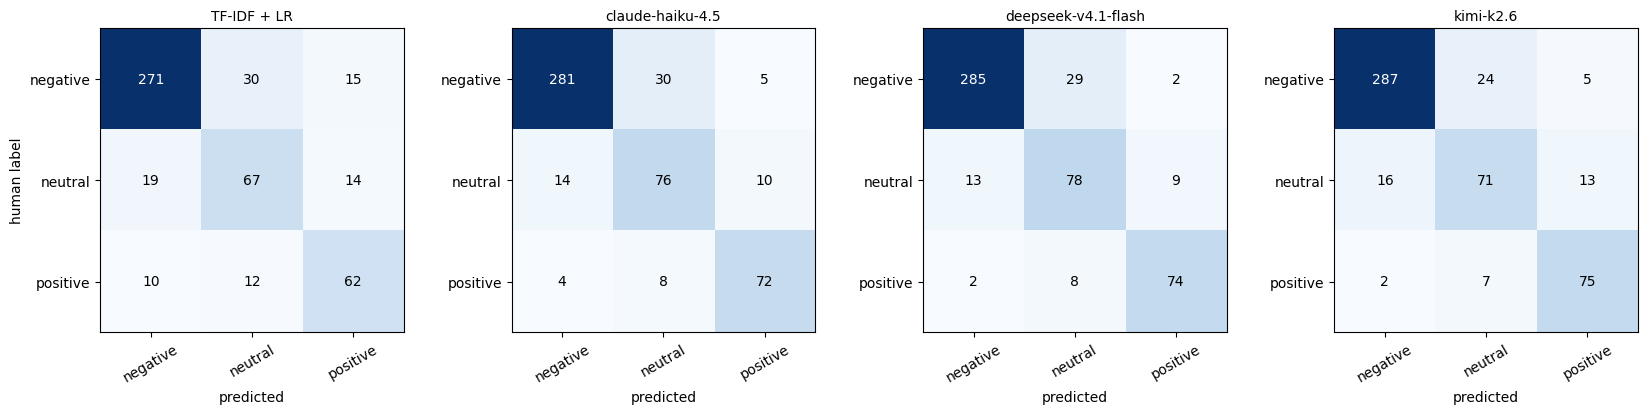

In [26]:
approaches = {"TF-IDF + LR": results["pred_baseline"]}
approaches.update({short(m): results[f"{short(m)}:sentiment"] for m in MODELS})

fig, axes = plt.subplots(1, len(approaches), figsize=(4.2 * len(approaches), 4))
for ax, (name, pred) in zip(np.atleast_1d(axes), approaches.items()):
    ok = pred.notna()
    cm = confusion_matrix(y[ok], pred[ok], labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(3), LABELS, rotation=30)
    ax.set_yticks(range(3), LABELS)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("predicted")
np.atleast_1d(axes)[0].set_ylabel("human label")
plt.tight_layout()
plt.show()

### 8c. Complaint reasons

For tweets that both the human annotators and the model call negative, how often does the model pick the same complaint reason? Tweets whose human reason is "Can't Tell" are excluded, because there is no clear answer to match.

In [27]:
reason_rows = []
for m in MODELS:
    s = short(m)
    both_neg = results[(results["airline_sentiment"] == "negative") &
                       (results[f"{s}:sentiment"] == "negative") &
                       (results["negativereason"] != "Can't Tell")]
    reason_rows.append({"model": s, "tweets compared": len(both_neg),
                        "reason accuracy": (both_neg["negativereason"] == both_neg[f"{s}:negative_reason"]).mean()})
pd.DataFrame(reason_rows).round(3)

,model,tweets compared,reason accuracy
0,claude-haiku-4.5,246,0.683
1,deepseek-v4.1-flash,249,0.695
2,kimi-k2.6,251,0.677


In [28]:
# Which complaint reasons get confused? (first model)
s = short(MODELS[0])
both_neg = results[(results["airline_sentiment"] == "negative") & (results[f"{s}:sentiment"] == "negative")]
pd.crosstab(both_neg["negativereason"], both_neg[f"{s}:negative_reason"],
            rownames=["human reason"], colnames=[f"{s} reason"])

claude-haiku-4.5 reason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Lost Luggage,longlines
human reason,,,,,,,,,,
Bad Flight,15,2,0,1,0,1,0,2,0,0
Can't Tell,7,13,1,12,0,0,0,1,0,1
Cancelled Flight,0,1,14,1,0,0,0,2,1,0
Customer Service Issue,0,7,4,72,0,2,7,5,2,1
Damaged Luggage,0,1,0,1,3,0,0,0,0,0
Flight Attendant Complaints,4,0,0,5,0,5,0,0,1,0
Flight Booking Problems,1,0,0,2,0,0,11,0,0,0
Late Flight,7,3,0,3,0,0,1,37,0,0
Lost Luggage,1,2,1,0,0,0,0,1,11,0


### 8d. Does model accuracy depend on how sure the humans were?

The dataset records how confident the human annotators were in each label. If models do much worse on tweets where humans were unsure, some "errors" may be ambiguous tweets or even wrong human labels rather than model failures.

In [29]:
results["human agreement"] = np.where(results["airline_sentiment_confidence"] >= 0.99,
                                      "high (all annotators agreed)", "lower")
tab = {}
for name, pred in approaches.items():
    tab[name] = (pred == y).groupby(results["human agreement"]).mean()
tab = pd.DataFrame(tab).T
tab["tweets: high / lower"] = f"{(results['human agreement'] != 'lower').sum()} / {(results['human agreement'] == 'lower').sum()}"
tab.round(3)

human agreement,high (all annotators agreed),lower,tweets: high / lower
TF-IDF + LR,0.873,0.589,371 / 129
claude-haiku-4.5,0.930,0.651,371 / 129
deepseek-v4.1-flash,0.938,0.690,371 / 129
kimi-k2.6,0.938,0.659,371 / 129


### 8e. Is the model's own confidence meaningful?

A useful confidence score should be higher when the model is right. If it is, low-confidence tweets can be routed to a human reviewer.

In [30]:
bins = [0, 0.7, 0.85, 0.95, 1.0001]
names = ["< 0.70", "0.70-0.85", "0.85-0.95", ">= 0.95"]
calib = []
for m in MODELS:
    s = short(m)
    conf = results[f"{s}:confidence"]
    band = pd.cut(conf, bins=bins, labels=names, right=False)
    correct = results[f"{s}:sentiment"] == y
    g = pd.DataFrame({"band": band, "correct": correct}).groupby("band", observed=False)["correct"]
    calib.append(pd.DataFrame({"model": s, "tweets": g.size(), "accuracy": g.mean()}))
pd.concat(calib).reset_index().pivot(index="band", columns="model", values=["tweets", "accuracy"]).round(3)

tweets                                       accuracy                              
model     claude-haiku-4.5 deepseek-v4.1-flash kimi-k2.6 claude-haiku-4.5 deepseek-v4.1-flash kimi-k2.6
band                                                                                                   
< 0.70                11.0                36.0      13.0            0.727               0.528     0.769
0.70-0.85            136.0               145.0     127.0            0.699               0.807     0.701
0.85-0.95            289.0               243.0     259.0            0.920               0.926     0.911
>= 0.95               64.0                76.0     101.0            0.938               1.000     0.970

## Step 9. Consistency: does the same model give the same answer twice?

We label the first 100 test tweets again with the first model and compare the two runs. Even with temperature 0, some providers do not return identical answers every time.

In [31]:
m = MODELS[0]
subset = test.head(CONSISTENCY_SIZE)
run2 = label_dataset(m, subset, run="repeat").set_index("id")
run1 = predictions[m].set_index("id")
common = run1.index.intersection(run2.index)

agree = (run1.loc[common, "sentiment"] == run2.loc[common, "sentiment"]).mean()
kappa = cohen_kappa_score(run1.loc[common, "sentiment"], run2.loc[common, "sentiment"])
print(f"{short(m)}: sentiment identical in {agree:.1%} of {len(common)} tweets (Cohen's kappa {kappa:.3f})")

changed = common[run1.loc[common, "sentiment"] != run2.loc[common, "sentiment"]]
pd.DataFrame({"text": subset.set_index("id").loc[changed, "text"],
              "run 1": run1.loc[changed, "sentiment"], "run 2": run2.loc[changed, "sentiment"]})

anthropic/claude-haiku-4.5 [repeat]: 0 already saved, 100 to label
  batch done: 25/100
  batch done: 50/100
  batch done: 75/100
  batch done: 100/100
  finished: 100/100 tweets have a valid label
claude-haiku-4.5: sentiment identical in 100.0% of 100 tweets (Cohen's kappa 1.000)


,text,run 1,run 2
id,,,


## Step 10. Escalation: a label the dataset does not have

The human labels contain no urgency flag, so we cannot score escalation automatically. We can still compare the models with each other, and we export a sample for students to label by hand. Once the `hand_label` column is filled in (`true` or `false`), run the second cell to compute precision and recall.

In [32]:
esc = pd.DataFrame({short(m): results[f"{short(m)}:escalate"] for m in MODELS})
print("Share of tweets each model would escalate:")
print(esc.astype(float).mean().round(3).to_string(), "\n")

if len(MODELS) > 1:
    pairs = [(a, b) for i, a in enumerate(esc.columns) for b in esc.columns[i + 1:]]
    for a, b in pairs:
        ok = esc[a].notna() & esc[b].notna()
        print(f"{a} vs {b}: agree on {(esc.loc[ok, a] == esc.loc[ok, b]).mean():.1%} of tweets")

# The template hides the model answers so that they do not influence the hand labels.
template = results[["id", "text"]].sample(50, random_state=RANDOM_SEED)
template["hand_label"] = ""
template_path = RESULTS_DIR / "escalation_hand_labels.csv"
if not template_path.exists():          # never overwrite labels already typed in
    template.to_csv(template_path, index=False)
print(f"\nHand-labeling file: {template_path} (50 tweets, model answers hidden)")

Share of tweets each model would escalate:
claude-haiku-4.5       0.278
deepseek-v4.1-flash    0.246
kimi-k2.6              0.264 

claude-haiku-4.5 vs deepseek-v4.1-flash: agree on 92.0% of tweets
claude-haiku-4.5 vs kimi-k2.6: agree on 89.8% of tweets
deepseek-v4.1-flash vs kimi-k2.6: agree on 92.6% of tweets

Hand-labeling file: /Users/shailendra/Documents/Data Science/Python/Code/LLM Sentiment Analysis/results/escalation_hand_labels.csv (50 tweets, model answers hidden)


In [33]:
# Run after filling in the hand_label column with true or false.
hand = pd.read_csv(RESULTS_DIR / "escalation_hand_labels.csv")
hand = hand[hand["hand_label"].astype(str).str.lower().isin(["true", "false"])]
if hand.empty:
    print("No hand labels yet.")
else:
    truth = hand["hand_label"].astype(str).str.lower() == "true"
    model_esc = results.set_index("id")
    for m in MODELS:
        pred = hand["id"].map(model_esc[f"{short(m)}:escalate"]).astype(str).str.lower() == "true"
        tp = (pred & truth).sum()
        precision = tp / pred.sum() if pred.sum() else np.nan
        recall = tp / truth.sum() if truth.sum() else np.nan
        print(f"{short(m)}: precision {precision:.2f}, recall {recall:.2f} (n={len(hand)})")

No hand labels yet.


## Step 11. Error analysis

The file below lists every test tweet where at least one model disagrees with the human label. Students add a category for each row, for example:

* **model error**: the model is clearly wrong
* **ambiguous**: reasonable people could disagree
* **human label wrong**: the model is right and the gold label is not
* **sarcasm**, **mixed sentiment**, or **question with a complaint**

In [34]:
cols = ["id", "text", "airline_sentiment", "airline_sentiment_confidence", "pred_baseline"] + \
       [f"{short(m)}:{c}" for m in MODELS for c in ("sentiment", "rationale")]
wrong_any = np.column_stack([results[f"{short(m)}:sentiment"] != y for m in MODELS]).any(axis=1)
errors = results.loc[wrong_any, cols].copy()
errors["error_category"] = ""
errors.to_csv(RESULTS_DIR / "disagreements_for_review.csv", index=False)
results.to_csv(RESULTS_DIR / "all_predictions.csv", index=False)

print(f"{len(errors)} of {len(results)} test tweets have at least one model disagreeing with the human label.")
print("Saved results/disagreements_for_review.csv and results/all_predictions.csv\n")
errors[["text", "airline_sentiment"] + [f"{short(m)}:sentiment" for m in MODELS]].head(15)

98 of 500 test tweets have at least one model disagreeing with the human label.
Saved results/disagreements_for_review.csv and results/all_predictions.csv



,text,airline_sentiment,claude-haiku-4.5:sentiment,deepseek-v4.1-flash:sentiment,kimi-k2.6:sentiment
0,@JetBlue so technically I could drive to JFK now and put in. Request for tomorrow's flight?,negative,neutral,neutral,neutral
12,@united my reservation were changed so that I can longer make my connecting flight. How can I change this without in...,neutral,negative,negative,negative
14,@USAirways but i bougth mc caren to jfk with same agency and delta airways . Delta refund money but usairways doesnt...,neutral,negative,negative,negative
26,.@AmericanAir how about connecting me with a customer service rep? I'd rather speak to a person than a computer. Tha...,negative,neutral,neutral,neutral
31,"@USAirways ah, and I was only given one shuttle voucher, so if I do ever get back to the airport you'll be getting t...",neutral,negative,negative,negative
33,@JetBlue thanks! I'll do it.,positive,neutral,positive,neutral
39,@SouthwestAir how often are airplane seats/tray tables cleaned and sanitized? rather have air purifier and clean sea...,negative,neutral,negative,neutral
58,@USAirways Mad love http://t.co/4ojrSDWPkK NYC-,neutral,positive,positive,positive
67,@SouthwestAir reviewing your oversize policy. Hardcase golfbags are free if under weight. How do we add guitars and ...,negative,neutral,neutral,neutral
68,@united cleaning a regional jet takes an hour?,negative,neutral,negative,negative


## Summary and discussion questions

Use the comparison table from Step 8a together with the analyses above.

1. Which approach would you recommend to the airline's head of customer experience, and why? Consider accuracy, cost per 1,000 tweets, speed, consistency, and data privacy.
2. The baseline costs nothing per tweet but needed 13,800 labeled examples. What would it cost the airline to create that training data, and how does that change the comparison?
3. Where do the models disagree most with the human labels? How many of those disagreements are really model errors?
4. Is the model's confidence score useful enough to decide which tweets a human should review?
5. The dataset is public and widely used. How might that affect the LLM results, and how could you test the models on data they cannot have seen?
6. Which parts of this workflow need a human, and why?